# 3. Microstructure after furnace cooling and air cooling

The transformation model is the semi-empirical Kirkaldy-Venugopalan / Li et al. (1998) kinetics, written
from the equations and integrated with Scheil's additivity rule, with the thermodynamic start conditions of
Collins et al. (2023). Cooling paths come from a heat balance: a furnace cool, or a bar of given diameter
cooling in still air (convection + radiation, temperature-dependent heat capacity).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
R = ROOT / "results"; FIG = ROOT / "figures"
def fig(name, width=1000):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

## Validation against measured dilatometry
Start temperatures of each constituent at nine cooling rates for EN3B, EN8 and SA-540 (Collins et al.).
The second block compares this implementation with the authors' own published Li-model numbers.

In [2]:
pd.read_csv(R / "s03_kinetics_summary.csv")

,start,model,n,bias_C,MAE_C
0,ferrite,this work,18,4.22,15.7
1,ferrite,Collins et al. Li model,16,9.62,11.3
2,ferrite,this work vs published Li,17,1.22,1.22
3,pearlite,this work,10,-10.8,22.6
4,pearlite,Collins et al. Li model,9,25.8,25.8
5,pearlite,this work vs published Li,10,-36.6,36.6
6,bainite,this work,5,-19.9,71.3
7,bainite,Collins et al. Li model,5,67.4,67.4
8,bainite,this work vs published Li,7,-81.3,81.3
9,martensite,this work,7,-2.85,7.42


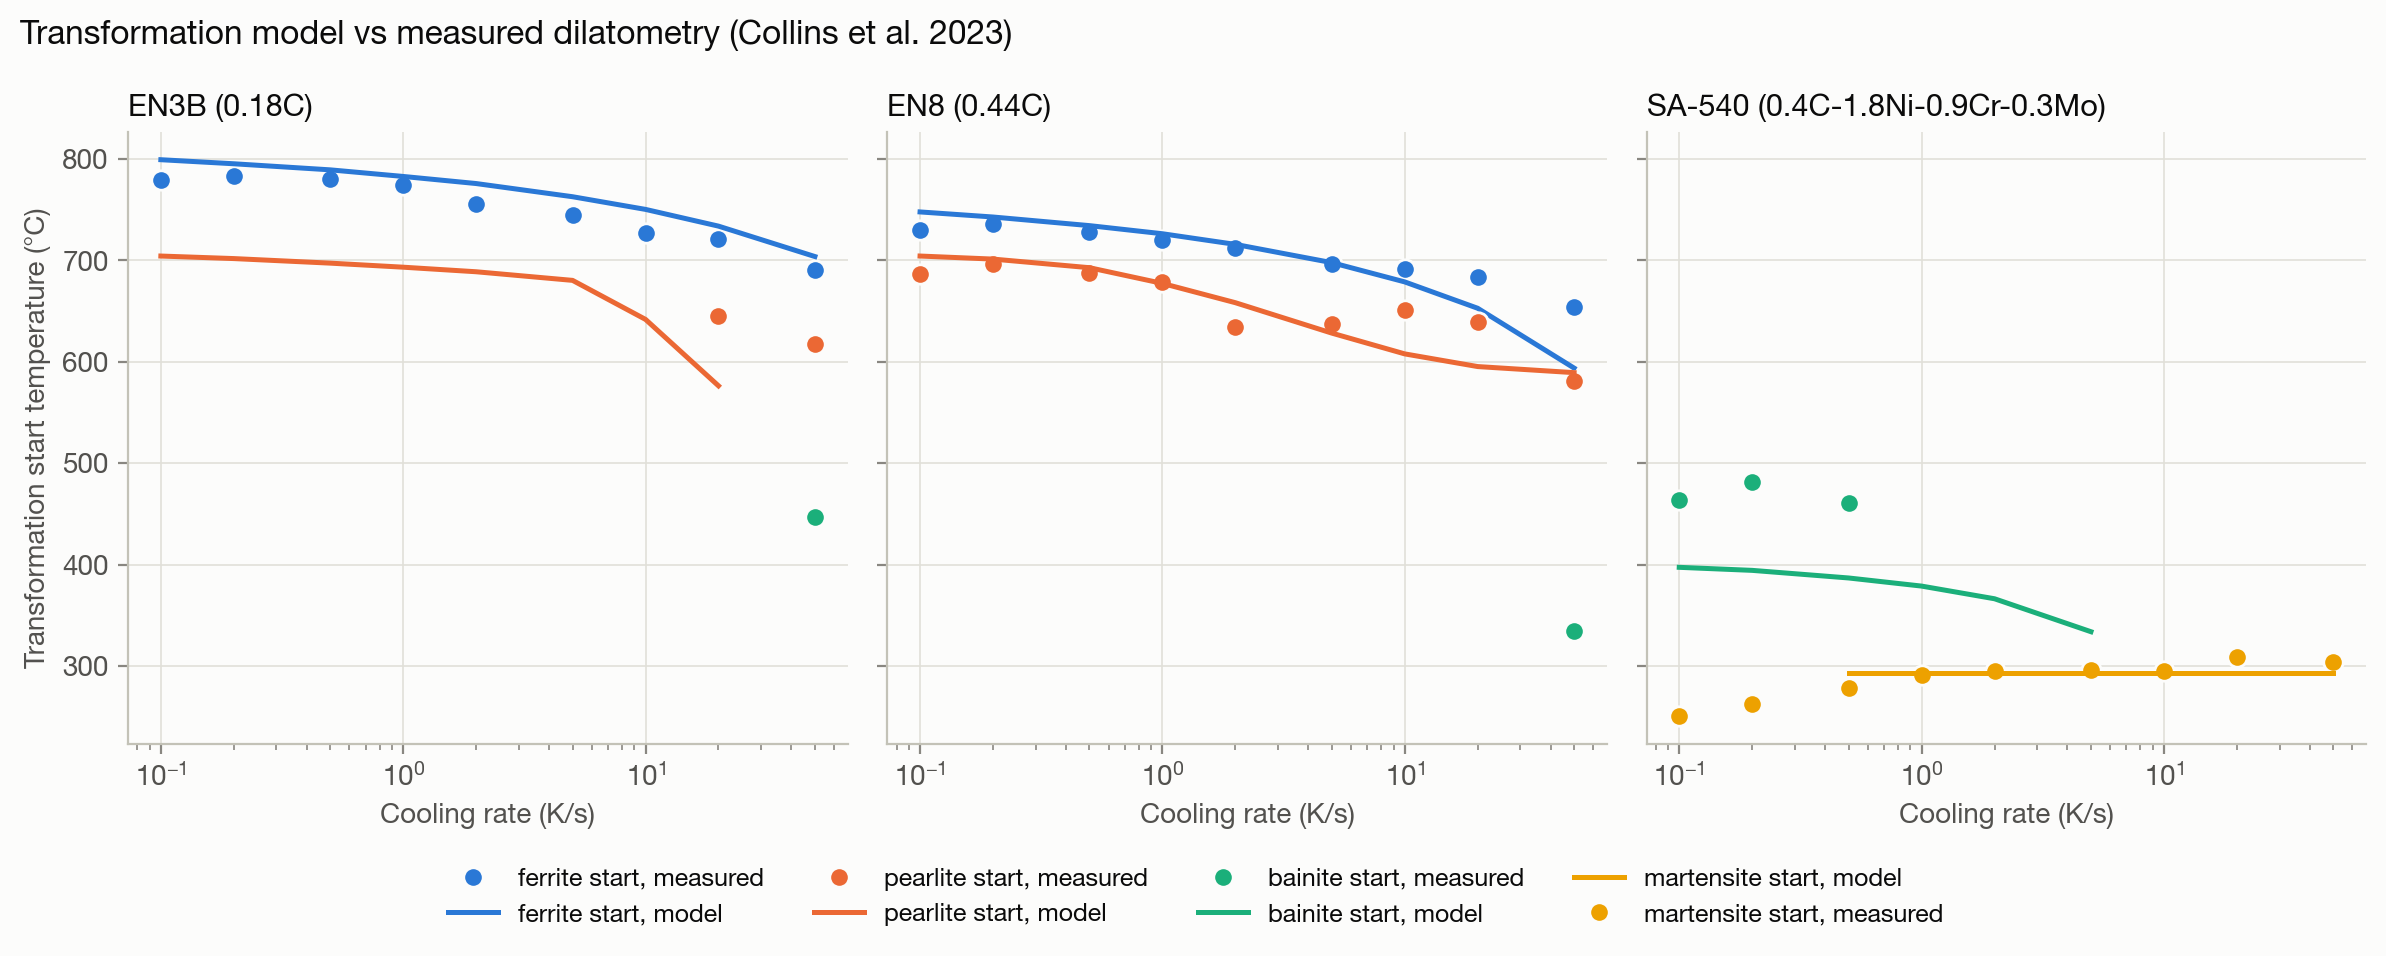

In [3]:
fig("fig07_kinetics_validation")

## Calibrating the cooling conditions of the handbook data
The handbook does not state how fast its bars cooled. Using physics only (no ML), the hardness error of the
normalized rows is large for small bars and flat between about 50 and 80 mm bars in still air; 50 mm (about
0.5 K/s at 700 C) is taken at the start of that flat region. For the annealed rows the error hardly changes
below 0.01 K/s, and 0.005 K/s (18 K/h), the usual full-annealing furnace cool, is taken.

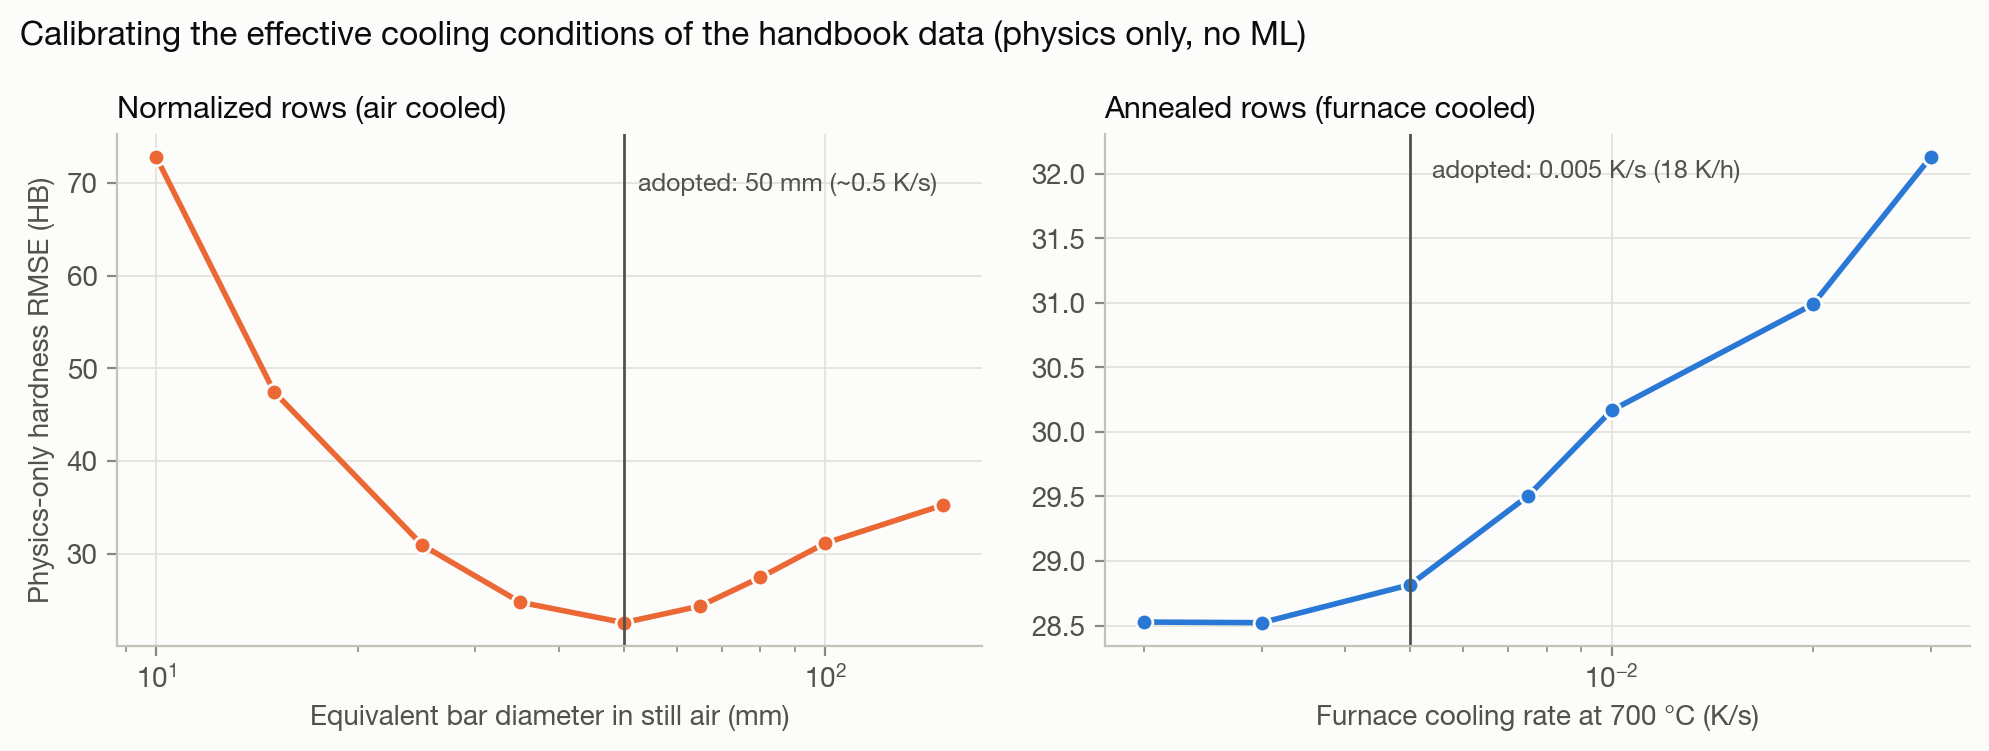

In [4]:
fig("fig08_cooling_calibration", 900)

## CCT diagrams with the two cooling paths
The furnace path passes through the ferrite and pearlite fields of every steel shown. The air path does so
for plain-carbon steels but crosses the bainite (and martensite) fields of the hardenable Cr-Mo and
Ni-Cr-Mo steels - the central difference between the categories.

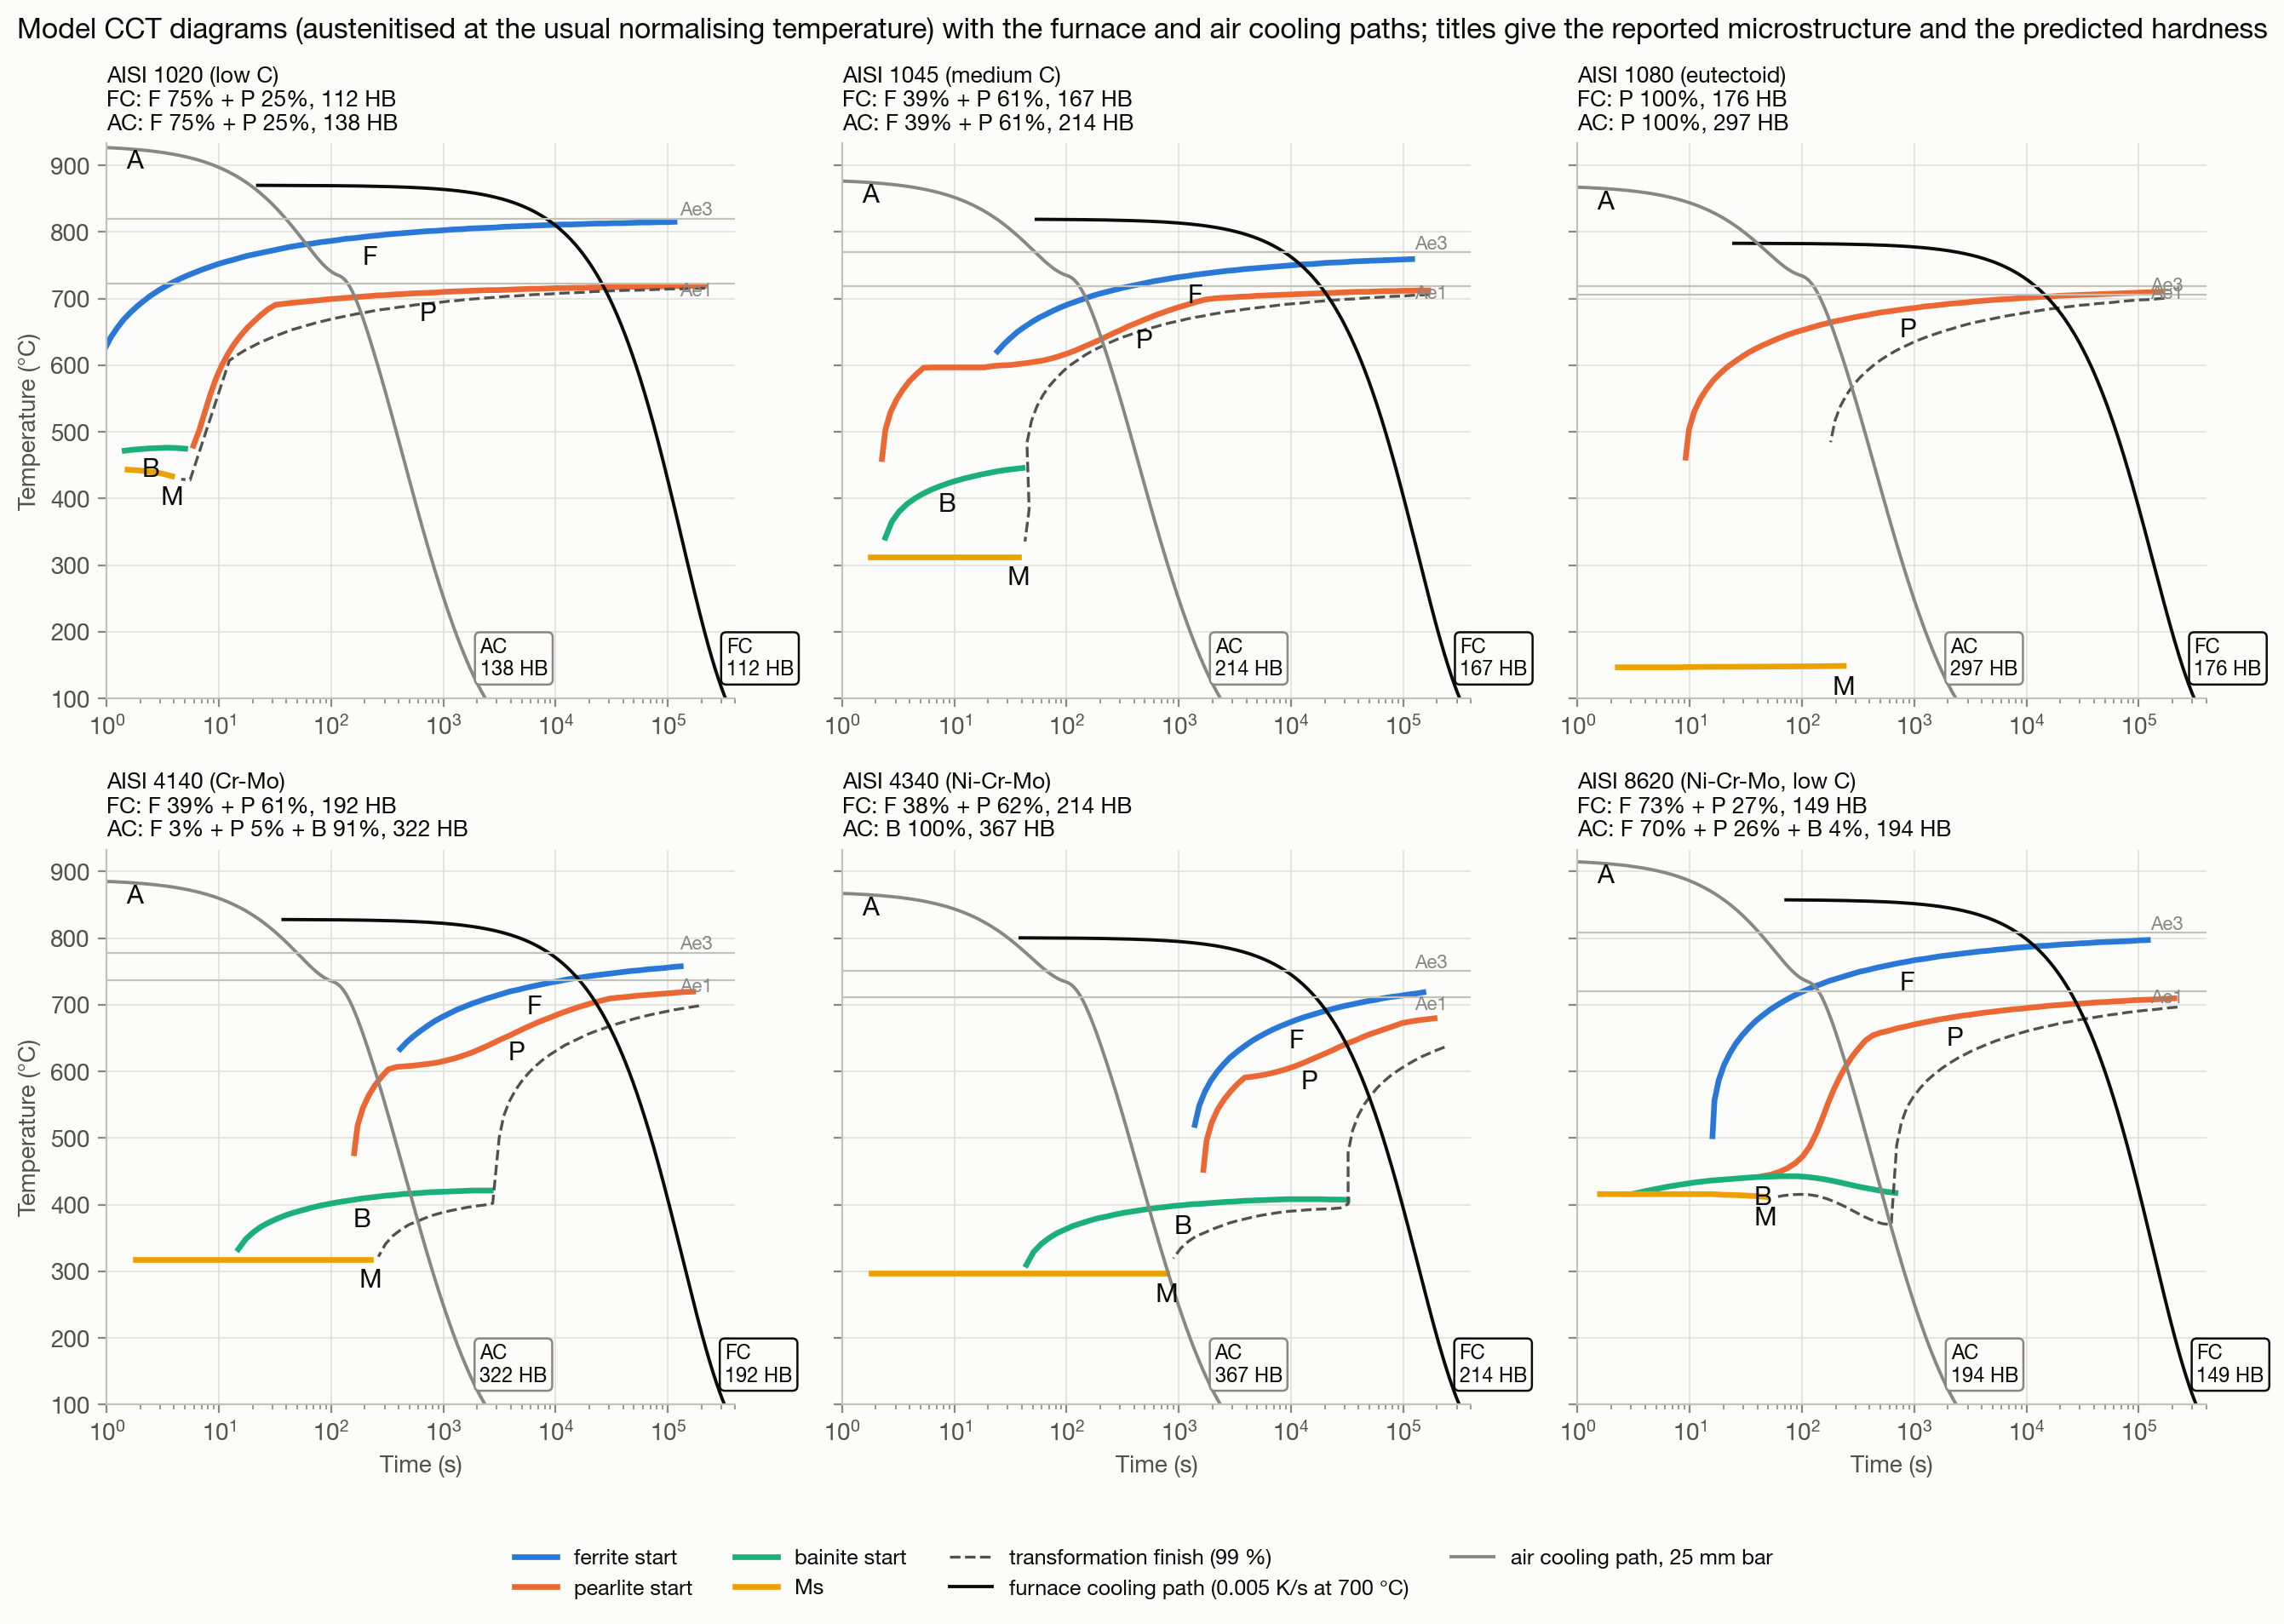

In [5]:
fig("fig09_cct_with_cooling_paths")

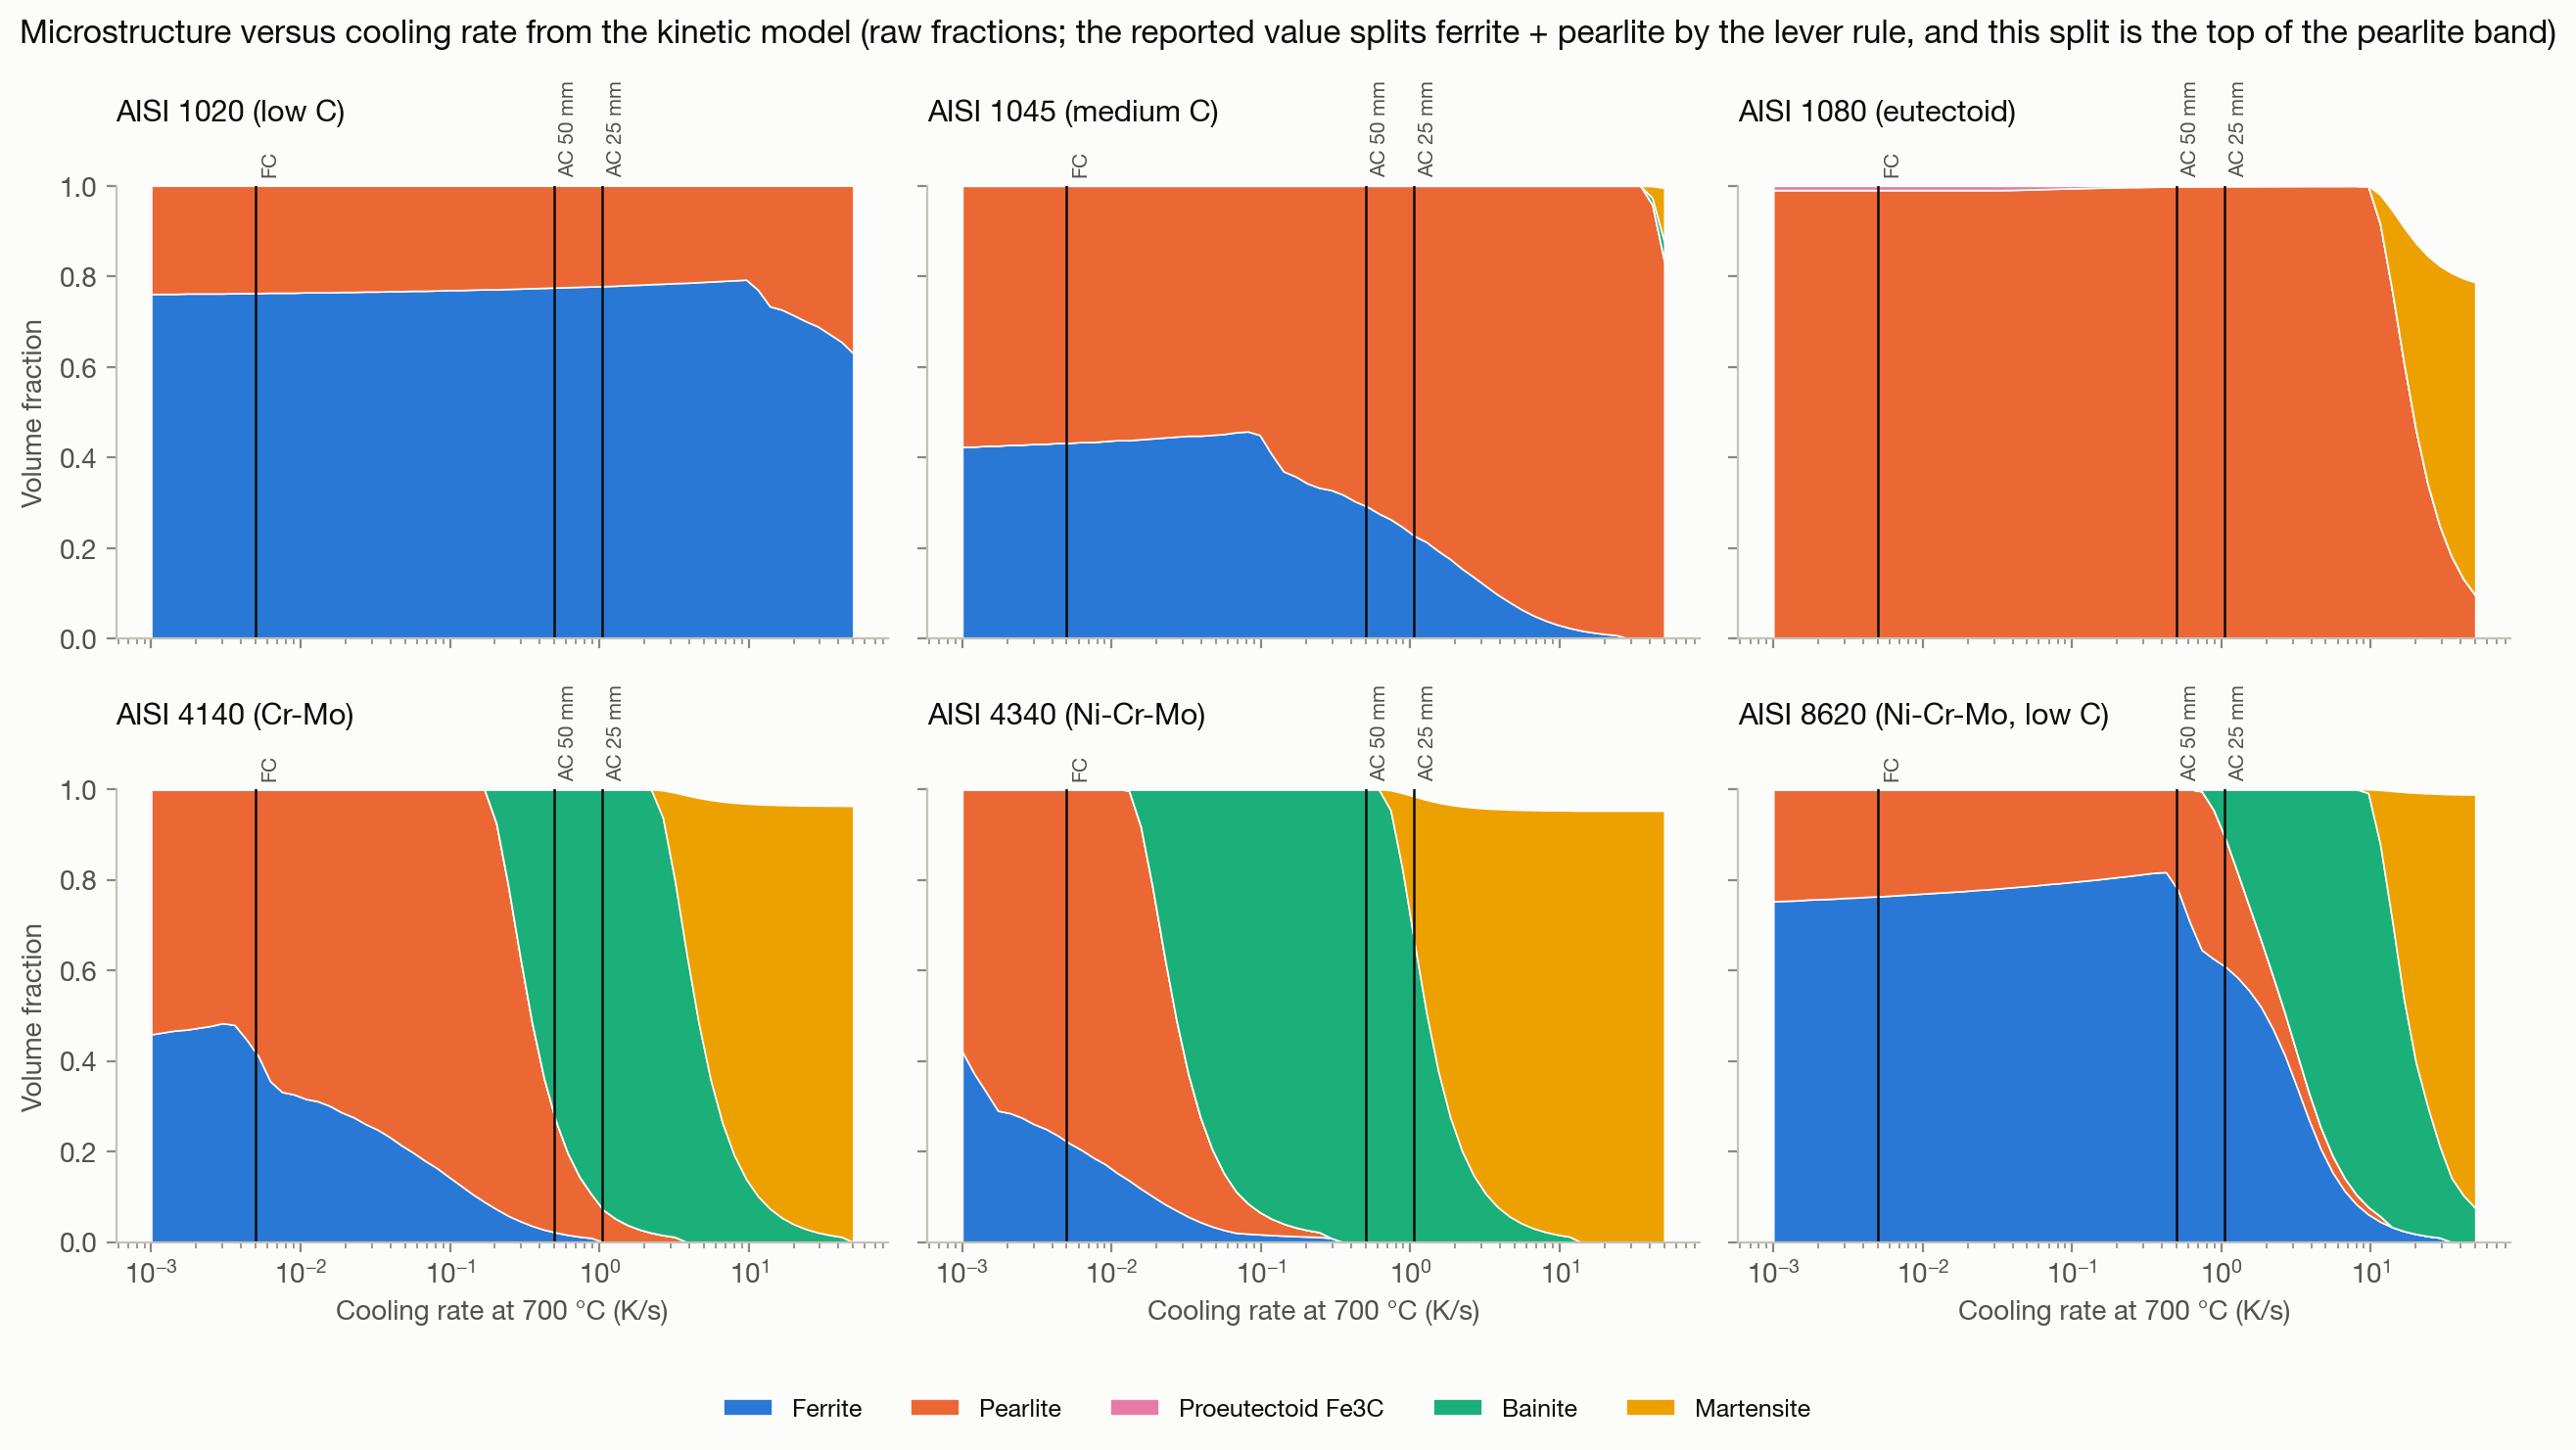

In [6]:
fig("fig10_microstructure_vs_cooling_rate")

## The two routes as cooling curves
Furnace cooling at 0.005 K/s, still-air cooling of bars of 10 to 150 mm, and three positions of a Jominy
bar. A still-air 25 mm bar has a mean 800-500 °C rate of about 0.9 K/s, the value measured for a 25 mm bar in
a patent study (0.89 K/s).

In [7]:
pd.read_csv(R / "s03_cooling_paths.csv")

,path,rate_700C_K_s,t85_s
0,furnace cooling,0.005,6.61e+04
1,"still air, 10 mm bar",2.76,125
2,"still air, 25 mm bar",1.05,332
3,"still air, 50 mm bar",0.505,692
4,"still air, 100 mm bar",0.245,1.43e+03
5,"still air, 150 mm bar",0.16,2.19e+03
6,Jominy J4,59.8,6.42
7,Jominy J16,8.04,50.4
8,Jominy J32,3,135


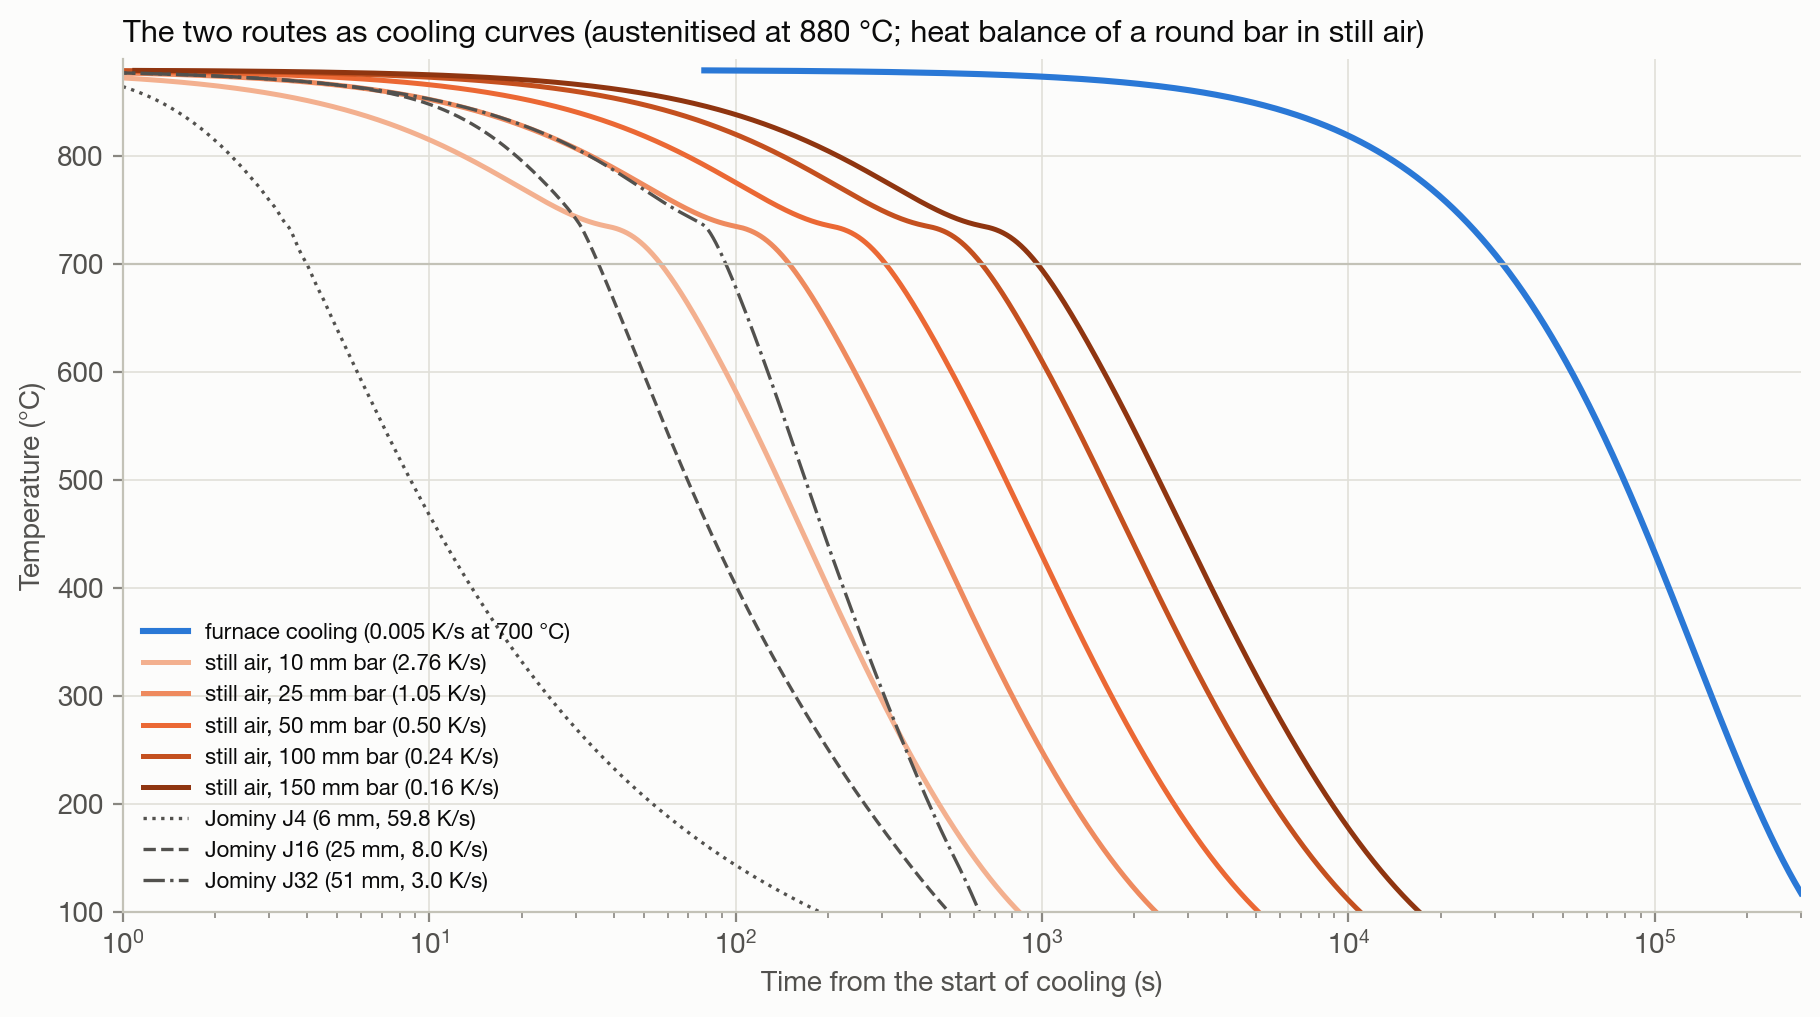

In [8]:
fig("fig27_cooling_paths", 850)

## 423 measured CCT points of 19 low-alloy steels
Phase fractions and hardness after continuous cooling, from the Rose and Hougardy atlas as tabulated in two
open (CC BY) papers. The model is good for quench-like cooling and weaker in the slow-to-intermediate range
where bainite competes with ferrite and pearlite.

In [9]:
pd.read_csv(R / "s03_cct_atlas_summary.csv")

,subset,n,steels,MAE_ferrite_pearlite,MAE_bainite,MAE_martensite,bias_ferrite_pearlite,HV_RMSE,HV_bias
0,all points,423,19,0.117,0.161,0.121,0.062,68.5,-9.57
1,t500 < 20 s (quench-like),113,19,0.0543,0.0861,0.139,0.0532,80.1,-35.1
2,t500 >= 20 s (air cooling of bars and slower),310,19,0.14,0.188,0.115,0.0652,63.8,-0.253


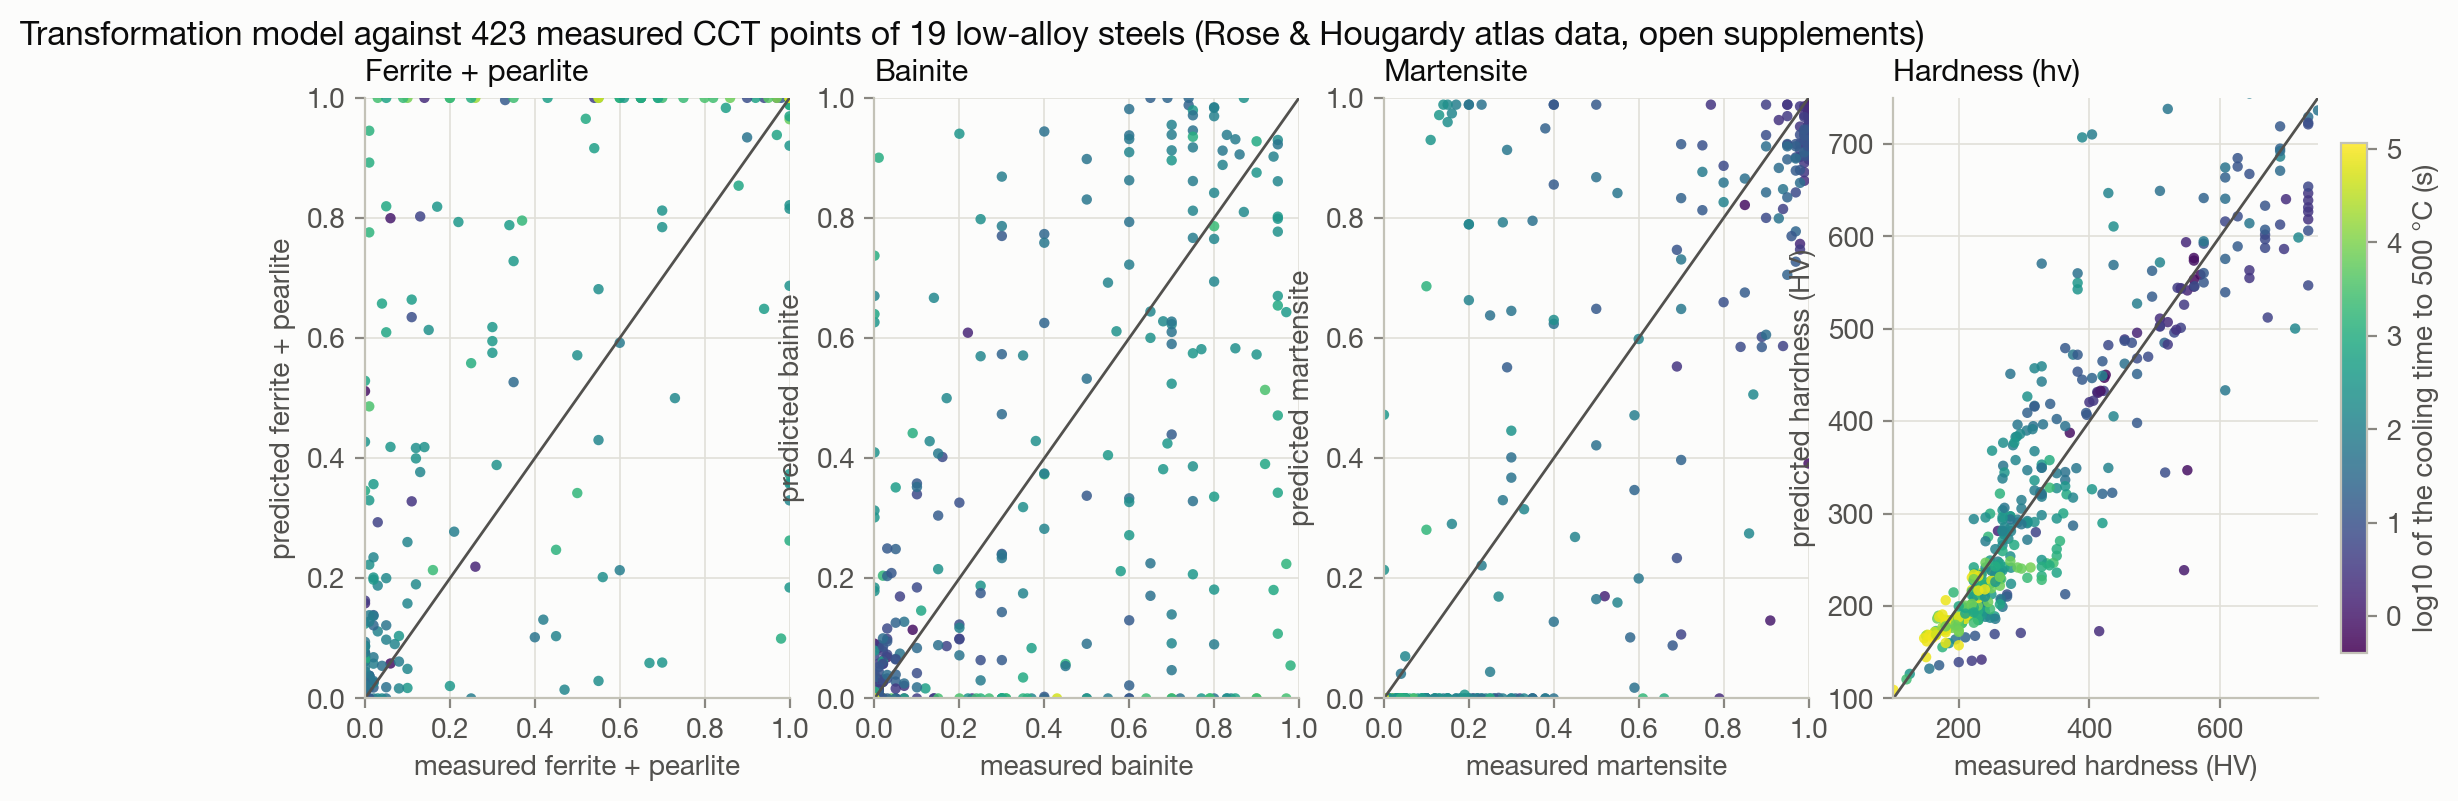

In [10]:
fig("fig28_cct_atlas_validation")

## Measured microstructures from the literature
The textbooks say that normalised steel holds more pearlite than annealed steel (the quasi-eutectoid
effect). The Li model shows this, but far too strongly for normalised medium-carbon bars, whose measured
fractions sit at or below the lever-rule value. We therefore report the lever split of the ferrite +
pearlite as the central value and the kinetic split as the top of a band, at every cooling rate. Starting
the pearlite incubation only inside the Hultgren region does not help (ablation below), and a faster ferrite
would fix the fractions but spoil the measured ferrite-start temperatures.

In [11]:
pd.read_csv(R / "s03_pearlite_coupling_ablation.csv")

,coupling,pearlite_start_MAE_C,pearlite_start_bias_C,pearlite_MAE_furnace,pearlite_MAE_air
0,incubation from Ae1 (published),22.6,-10.8,4.27,19
1,incubation inside the Hultgren region,24.1,-14.9,4.27,21.8


In [12]:
pd.read_csv(R / "s03_grain_size_check.csv")

,relation,n,MAE_um,bias_um,mean_error_factor,at_3um_floor
0,"Hodgson-Gibbs, both branches",20,16.9,-11.3,2.67,6
1,"Hodgson-Gibbs low-Ceq branch, Ceq held at 0.35...",20,15.2,-6.16,2.06,0


In [13]:
pd.read_csv(R / "s03_literature_pearlite_summary.csv")

,subset,estimate,n,MAE_pct_points,bias
0,furnace cooled,kinetic,7,4.27,-2.23
1,furnace cooled,lever,7,5.52,0.66
2,furnace cooled,best_estimate,7,5.52,0.66
3,air cooled,kinetic,9,19,12.3
4,air cooled,lever,9,12.4,1.73
5,air cooled,best_estimate,9,12.9,1.27
6,all,kinetic,16,12.6,5.94
7,all,lever,16,9.42,1.26
8,all,best_estimate,16,9.68,1


In [14]:
pd.read_csv(R / "s03_ferrite_factor_scan.csv")

,ferrite_rate_factor,ferrite_start_bias_C,ferrite_start_MAE_C,pearlite_MAE_furnace,pearlite_MAE_air
0,1,4.22,15.7,4.27,19
1,2,16.9,18.8,4.27,23.2
2,3,22.8,22.8,4.27,21.4
3,5,29,29,4.27,18.3
4,8,33.8,33.8,4.27,14.5
5,12,37.4,37.4,4.27,14.9


In [15]:
pd.read_csv(R / "s03_spacing_calibration.csv")

,n,sources,A_um,m,dT_range_K,loso_factor_power_law,loso_factor_constant_k,factor_marder_bramfitt_8.02
0,14,4,2.38,0.534,26-264,1.77,1.64,3.12


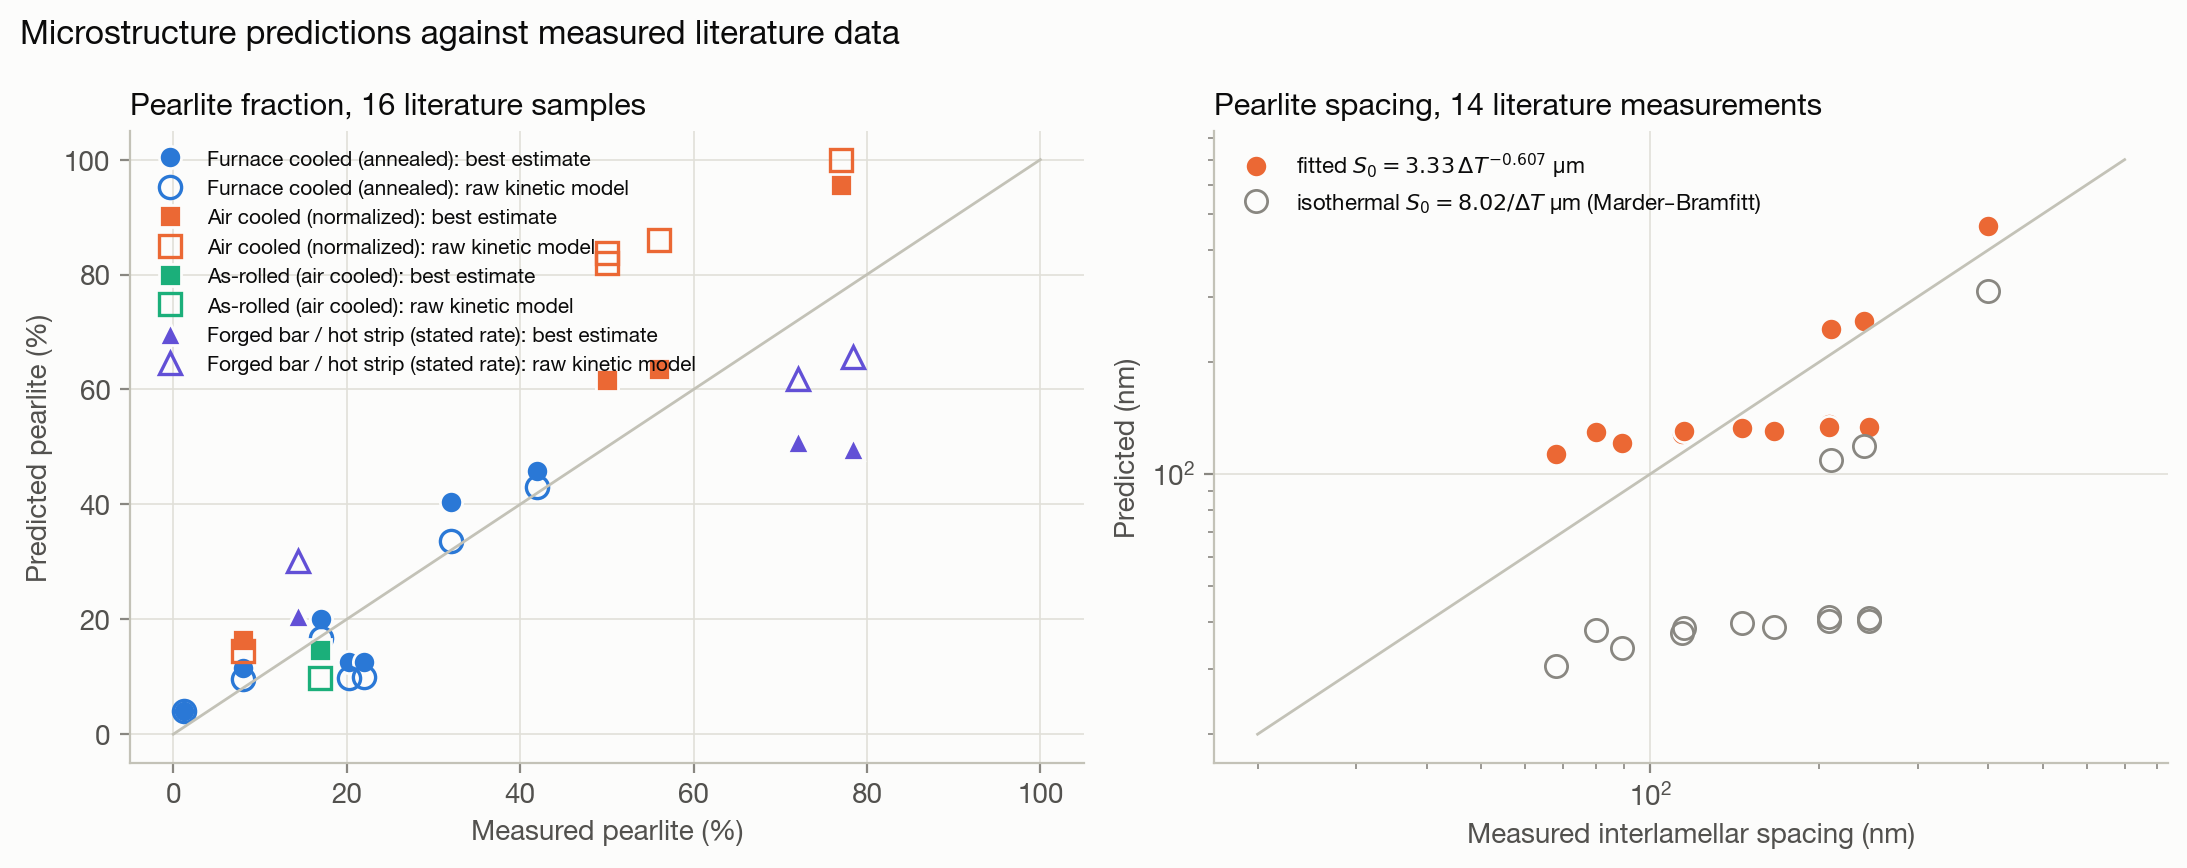

In [16]:
fig("fig11_microstructure_literature_validation", 900)